# 📊 SSC Student Result Analysis

## Comprehensive Student Performance Analysis

This notebook performs a complete analysis of SSC student results.

### Analysis Covered

1. 📋 Student Master Table
2. 👨‍🎓 Per-Student Performance
3. 📈 Overall Student Statistics
4. ✅❌ Pass / Fail Analysis
5. 📚 Subject-wise Analysis
6. 🎓 Subject-wise Grade Distribution
7. ❌ Failed Students & Failed Subjects
8. 🏆 Student Ranking by GPA
9. 👥 Group-wise Analysis
10. 🥇 Best & Weakest Subject per Student

### Libraries Used

- Pandas
- NumPy
- Matplotlib
- Seaborn

The analysis is performed directly inside this notebook.


In [22]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 50)

# # Seaborn visual style
# sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Load the Student Dataset

The student result data is embedded directly in this notebook.

The dataset contains:

- Student Roll
- Student Name
- Group
- Gender
- Class Teacher
- Result
- GPA
- Subject-wise marks


In [23]:
# ============================================================
# RAW STUDENT DATA
# ============================================================

csv_raw = """
Roll,Name,Group,Gender,Class Teacher,Result,GPA,Bangla,English,Mathematics,BGS,Physics,Chemistry,Biology,ICT,Physical Education ,Carrer Education,General Science,Agriculture Studies,Islam & Moral Ed,Geography,Civics,History
105239,Sheikh Talha,Science,Male,Dr. Jatka,PASS,4,126,136,47,62,72,71,85,43,48,48,,79,69,,,
105240,Tahia Sultana,Science,Female,Dr. Jatka,PASS,4.22,133,102,55,89,62,67,79,43,48,48,,81,83,,,
105241,Kazi Sadia Sultana Mahima,Science,Female,Dr. Jatka,PASS,4.11,116,105,61,84,67,71,77,45,48,48,,73,79,,,
105243,Toslima Begum,Science,Female,Dr. Jatka,PASS,3.78,112,94,41,82,61,64,78,44,48,48,,70,79,,,
105247,Kazi Mumina Akter Jui,Science,Female,Dr. Jatka,PASS,3.39,109,96,42,67,52,63,70,45,48,48,,69,52,,,
308975,Ariful Islam,Humanities,Male,Dr. Jatka,FAIL,0,75,0,34,,,,,37,,,39,0,0,45,0,0
308026,Md Riyad,Humanities,Male,Dr. Jatka,FAIL,0,76,0,34,,,,,37,47,47,45,55,39,34,47,45
308927,Mazedul Islam Naim,Humanities,Male,Dr. Jatka,FAIL,0,90,0,0,,,,,37,48,48,46,0,36,0,37,38
308978,Test,Humanities,Female,Dr. Jatka,FAIL,0,99,0,33,,,,,33,,,33,0,0,3,0,0
"""

# Read CSV data
df = pd.read_csv(io.StringIO(csv_raw))

# Clean column names
df.columns = df.columns.str.strip().str.replace(" ", "_", regex=False)

# Convert GPA to numeric
df["GPA"] = pd.to_numeric(df["GPA"], errors="coerce")

print(f"Dataset loaded successfully.")
print(f"Students : {len(df)}")
print(f"Columns  : {len(df.columns)}")

Dataset loaded successfully.
Students : 9
Columns  : 23


# 2. Data Overview

Before performing analysis, we inspect:

- Dataset dimensions
- Column names
- Data types
- Missing values
- Duplicate records


In [24]:
# ============================================================
# DATA OVERVIEW
# ============================================================

print("=" * 80)
print("DATASET SHAPE")
print("=" * 80)

print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

print("\n" + "=" * 80)
print("COLUMN NAMES")
print("=" * 80)

print(df.columns.tolist())

print("\n" + "=" * 80)
print("DATA TYPES")
print("=" * 80)

display(df.dtypes.to_frame("Data Type"))

print("\n" + "=" * 80)
print("MISSING VALUES")
print("=" * 80)

missing_values = df.isna().sum().sort_values(ascending=False)

display(missing_values[missing_values > 0].to_frame("Missing Values"))

print("\n" + "=" * 80)
print("DUPLICATE ROWS")
print("=" * 80)

print(f"Duplicate rows: {df.duplicated().sum()}")

DATASET SHAPE
Rows    : 9
Columns : 23

COLUMN NAMES
['Roll', 'Name', 'Group', 'Gender', 'Class_Teacher', 'Result', 'GPA', 'Bangla', 'English', 'Mathematics', 'BGS', 'Physics', 'Chemistry', 'Biology', 'ICT', 'Physical_Education', 'Carrer_Education', 'General_Science', 'Agriculture_Studies', 'Islam_&_Moral_Ed', 'Geography', 'Civics', 'History']

DATA TYPES


,Data Type
Roll,int64
Name,str
Group,str
Gender,str
Class_Teacher,str
Result,str
GPA,float64
Bangla,int64
English,int64
Mathematics,int64



MISSING VALUES


,Missing Values
History,5
Civics,5
Geography,5
General_Science,5
Chemistry,4
Biology,4
BGS,4
Physics,4
Physical_Education,2
Carrer_Education,2



DUPLICATE ROWS
Duplicate rows: 0


# 3. Define Subjects

Different groups have different subjects.

For example:

### Science

- Bangla
- English
- Mathematics
- BGS
- Physics
- Chemistry
- Biology
- ICT

### Humanities

- Bangla
- English
- Mathematics
- BGS
- ICT
- Agriculture Studies
- Islam & Moral Education
- Geography
- Civics
- History

Missing values are therefore treated as **not applicable**, rather than failures.


In [25]:
# ============================================================
# SUBJECT DEFINITIONS
# ============================================================

subject_columns = [
    "Bangla",
    "English",
    "Mathematics",
    "BGS",
    "Physics",
    "Chemistry",
    "Biology",
    "ICT",
    "Physical_Education",
    "Carrer_Education",
    "General_Science",
    "Agriculture_Studies",
    "Islam_&_Moral_Ed",
    "Geography",
    "Civics",
    "History",
]

# Keep only subjects actually present in the dataset
subject_columns = [subject for subject in subject_columns if subject in df.columns]

# Convert marks to numeric
for subject in subject_columns:
    df[subject] = pd.to_numeric(df[subject], errors="coerce")

# Standard pass mark
PASS_MARK = 33

print("Subjects found in dataset:")
for i, subject in enumerate(subject_columns, start=1):
    print(f"{i:2}. {subject}")

Subjects found in dataset:
 1. Bangla
 2. English
 3. Mathematics
 4. BGS
 5. Physics
 6. Chemistry
 7. Biology
 8. ICT
 9. Physical_Education
10. Carrer_Education
11. General_Science
12. Agriculture_Studies
13. Islam_&_Moral_Ed
14. Geography
15. Civics
16. History


# 4. Per-Student Performance

For every student we calculate:

- Number of subjects attempted
- Total marks
- Average marks
- Highest mark
- Lowest mark
- Passed subjects
- Failed subjects
- Subject pass rate
- Best subject
- Weakest subject

This gives us a complete performance profile for each student.


In [26]:
# ============================================================
# PER-STUDENT PERFORMANCE
# ============================================================

performance = df[["Roll", "Name", "Group", "Gender", "Result", "GPA"]].copy()

# Number of subjects for which marks exist
performance["Subjects_Attempted"] = df[subject_columns].notna().sum(axis=1)

# Total marks
performance["Total_Marks"] = df[subject_columns].sum(axis=1, skipna=True)

# Average marks
performance["Average_Marks"] = df[subject_columns].mean(axis=1, skipna=True).round(2)

# Highest mark
performance["Highest_Mark"] = df[subject_columns].max(axis=1, skipna=True)

# Lowest mark
performance["Lowest_Mark"] = df[subject_columns].min(axis=1, skipna=True)

# Passed subjects
performance["Passed_Subjects"] = df[subject_columns].ge(PASS_MARK).sum(axis=1)

# Failed subjects
performance["Failed_Subjects"] = df[subject_columns].lt(PASS_MARK).sum(axis=1)

# Subject pass rate
performance["Subject_Pass_Rate_%"] = (
    performance["Passed_Subjects"] / performance["Subjects_Attempted"] * 100
).round(2)

# Best subject
performance["Best_Subject"] = df[subject_columns].idxmax(axis=1)

# Weakest subject
performance["Weakest_Subject"] = df[subject_columns].idxmin(axis=1)

display(performance)

,Roll,Name,Group,Gender,Result,GPA,Subjects_Attempted,Total_Marks,Average_Marks,Highest_Mark,Lowest_Mark,Passed_Subjects,Failed_Subjects,Subject_Pass_Rate_%,Best_Subject,Weakest_Subject
0,105239,Sheikh Talha,Science,Male,PASS,4.00,12,886.0,73.83,136.0,43.0,12,0,100.00,English,ICT
1,105240,Tahia Sultana,Science,Female,PASS,4.22,12,890.0,74.17,133.0,43.0,12,0,100.00,Bangla,ICT
2,105241,Kazi Sadia Sultana Mahima,Science,Female,PASS,4.11,12,874.0,72.83,116.0,45.0,12,0,100.00,Bangla,ICT
3,105243,Toslima Begum,Science,Female,PASS,3.78,12,821.0,68.42,112.0,41.0,12,0,100.00,Bangla,Mathematics
4,105247,Kazi Mumina Akter Jui,Science,Female,PASS,3.39,12,761.0,63.42,109.0,42.0,12,0,100.00,Bangla,Mathematics
5,308975,Ariful Islam,Humanities,Male,FAIL,0.00,10,230.0,23.00,75.0,0.0,5,5,50.00,Bangla,English
6,308026,Md Riyad,Humanities,Male,FAIL,0.00,12,506.0,42.17,76.0,0.0,11,1,91.67,Bangla,English
7,308927,Mazedul Islam Naim,Humanities,Male,FAIL,0.00,12,380.0,31.67,90.0,0.0,8,4,66.67,Bangla,English
8,308978,Test,Humanities,Female,FAIL,0.00,10,201.0,20.10,99.0,0.0,4,6,40.00,Bangla,English


# 5. Overall Student Statistics

This section provides a high-level overview of the complete class:

- Total students
- Passed students
- Failed students
- Pass rate
- Fail rate
- Average GPA
- Highest GPA
- Lowest GPA
- Average marks
- Highest mark
- Lowest mark


In [27]:
# ============================================================
# OVERALL STUDENT STATISTICS
# ============================================================

total_students = len(df)

passed_students = df["Result"].str.upper().eq("PASS").sum()

failed_students = df["Result"].str.upper().eq("FAIL").sum()

pass_rate = passed_students / total_students * 100

fail_rate = failed_students / total_students * 100

overall_statistics = pd.DataFrame(
    {
        "Statistic": [
            "Total Students",
            "Passed Students",
            "Failed Students",
            "Pass Rate (%)",
            "Fail Rate (%)",
            "Average GPA",
            "Highest GPA",
            "Lowest GPA",
            "Average Marks",
            "Highest Mark",
            "Lowest Mark",
        ],
        "Value": [
            total_students,
            passed_students,
            failed_students,
            round(pass_rate, 2),
            round(fail_rate, 2),
            round(df["GPA"].mean(), 2),
            round(df["GPA"].max(), 2),
            round(df["GPA"].min(), 2),
            round(performance["Average_Marks"].mean(), 2),
            df[subject_columns].max().max(),
            df[subject_columns].min().min(),
        ],
    }
)

display(overall_statistics)

,Statistic,Value
0,Total Students,9.00
1,Passed Students,5.00
2,Failed Students,4.00
3,Pass Rate (%),55.56
4,Fail Rate (%),44.44
5,Average GPA,2.17
6,Highest GPA,4.22
7,Lowest GPA,0.00
8,Average Marks,52.18
9,Highest Mark,136.00


# 6. Pass / Fail Analysis

We compare the number and percentage of:

- PASS students
- FAIL students

This provides a quick overview of overall academic success.


In [28]:
# ============================================================
# PASS / FAIL ANALYSIS
# ============================================================

pass_fail = (
    df["Result"]
    .str.upper()
    .value_counts()
    .rename_axis("Result")
    .reset_index(name="Students")
)

pass_fail["Percentage_%"] = (pass_fail["Students"] / total_students * 100).round(2)

display(pass_fail)

,Result,Students,Percentage_%
0,PASS,5,55.56
1,FAIL,4,44.44


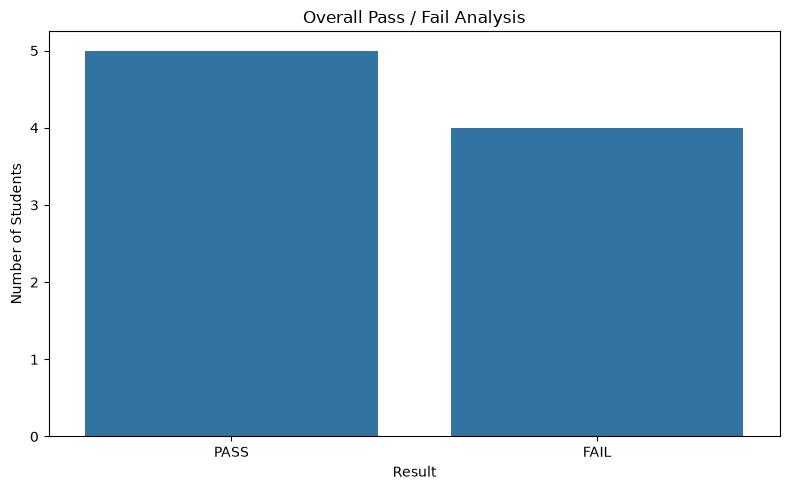

In [29]:
# ============================================================
# PASS / FAIL VISUALIZATION
# ============================================================

plt.figure(figsize=(8, 5))

sns.barplot(data=pass_fail, x="Result", y="Students")

plt.title("Overall Pass / Fail Analysis")
plt.xlabel("Result")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

# 7. Subject-wise Analysis

For every subject we calculate:

- Number of students with marks
- Average marks
- Highest mark
- Lowest mark
- Number passed
- Number failed
- Pass rate
- Fail rate

### Weakest Subject Definition

Subjects are sorted by:

1. Highest failure rate
2. Lowest average marks

Therefore, the weakest subjects appear at the top.


In [30]:
# ============================================================
# SUBJECT-WISE ANALYSIS
# ============================================================

subject_rows = []

for subject in subject_columns:

    # Ignore missing marks
    marks = df[subject].dropna()

    students = len(marks)

    passed = (marks >= PASS_MARK).sum()
    failed = (marks < PASS_MARK).sum()

    pass_rate_subject = passed / students * 100 if students > 0 else 0

    fail_rate_subject = failed / students * 100 if students > 0 else 0

    subject_rows.append(
        {
            "Subject": subject,
            "Students": students,
            "Average": round(marks.mean(), 2),
            "Highest": marks.max(),
            "Lowest": marks.min(),
            "Passed": passed,
            "Failed": failed,
            "Pass_Rate_%": round(pass_rate_subject, 2),
            "Fail_Rate_%": round(fail_rate_subject, 2),
        }
    )

subject_analysis = pd.DataFrame(subject_rows)

# Weakest first
subject_analysis = subject_analysis.sort_values(
    by=["Fail_Rate_%", "Average"], ascending=[False, True]
).reset_index(drop=True)

display(subject_analysis)

,Subject,Students,Average,Highest,Lowest,Passed,Failed,Pass_Rate_%,Fail_Rate_%
0,Geography,4,20.50,45.0,0.0,2,2,50.00,50.00
1,History,4,20.75,45.0,0.0,2,2,50.00,50.00
2,Civics,4,21.00,47.0,0.0,2,2,50.00,50.00
3,English,9,59.22,136.0,0.0,5,4,55.56,44.44
4,Agriculture_Studies,9,47.44,81.0,0.0,6,3,66.67,33.33
5,Islam_&_Moral_Ed,9,48.56,83.0,0.0,7,2,77.78,22.22
6,Mathematics,9,38.56,61.0,0.0,8,1,88.89,11.11
7,ICT,9,40.44,45.0,33.0,9,0,100.00,0.00
8,General_Science,4,40.75,46.0,33.0,4,0,100.00,0.00
9,Physical_Education,7,47.86,48.0,47.0,7,0,100.00,0.00


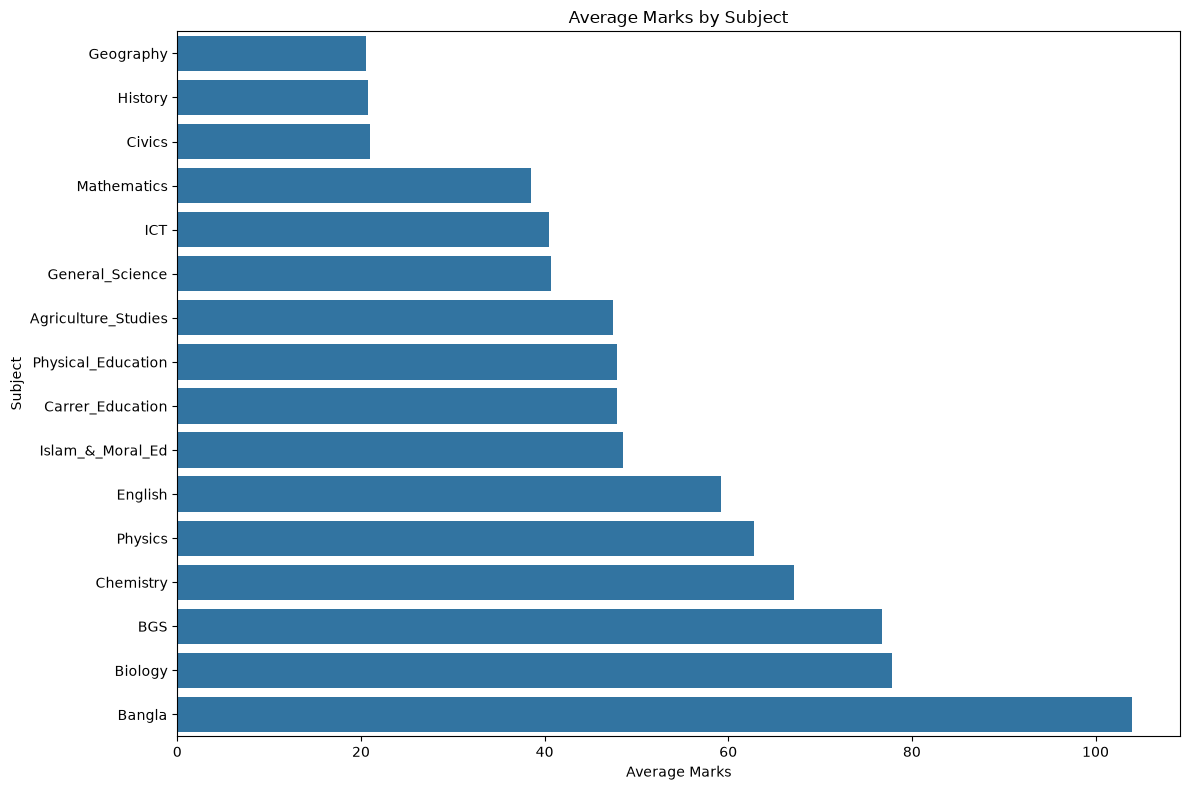

In [31]:
# ============================================================
# SUBJECT AVERAGE VISUALIZATION
# ============================================================

plot_average = subject_analysis.sort_values("Average", ascending=True)

plt.figure(figsize=(12, 8))

sns.barplot(data=plot_average, x="Average", y="Subject")

plt.title("Average Marks by Subject")
plt.xlabel("Average Marks")
plt.ylabel("Subject")

plt.tight_layout()
plt.show()

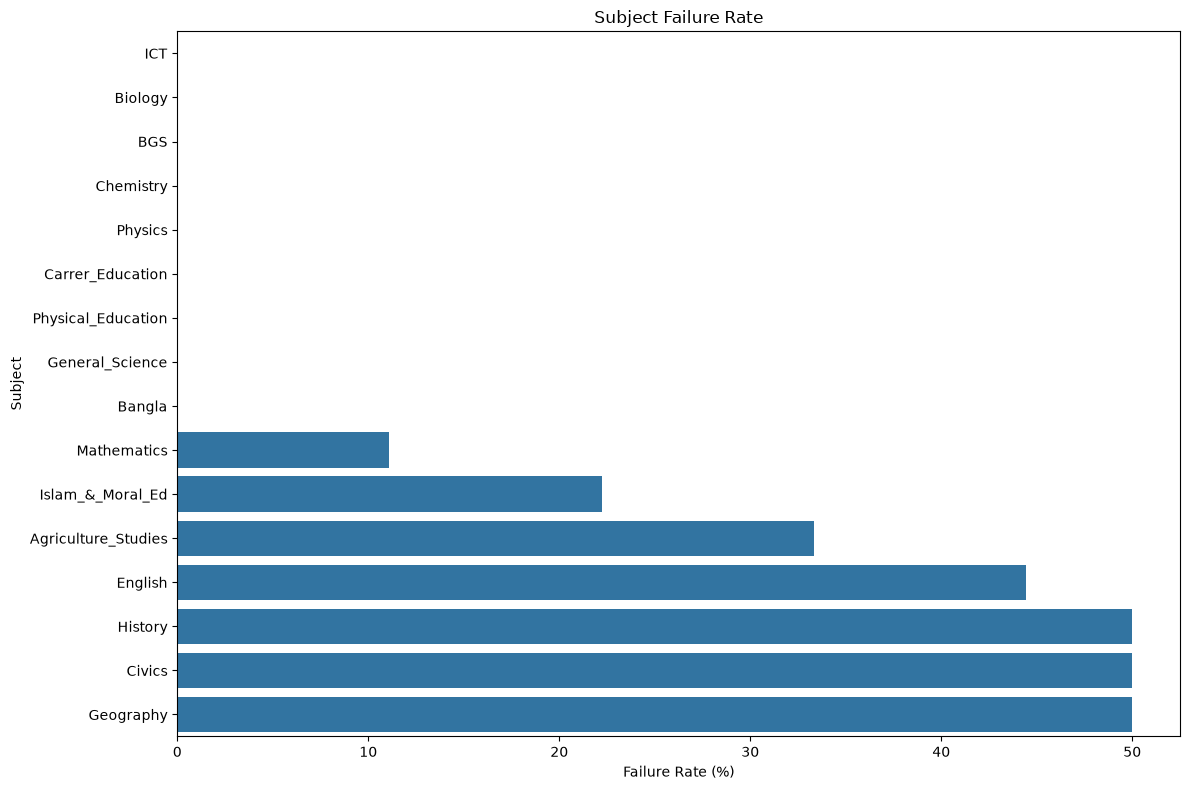

In [32]:
# ============================================================
# SUBJECT FAILURE RATE
# ============================================================

plot_failure = subject_analysis.sort_values("Fail_Rate_%", ascending=True)

plt.figure(figsize=(12, 8))

sns.barplot(data=plot_failure, x="Fail_Rate_%", y="Subject")

plt.title("Subject Failure Rate")
plt.xlabel("Failure Rate (%)")
plt.ylabel("Subject")

plt.tight_layout()
plt.show()

# 8. Subject-wise Grade Distribution

The following grading scale is used:

|  Marks | Grade |
| -----: | :---: |
| 80–100 |  A+   |
|  70–79 |   A   |
|  60–69 |  A-   |
|  50–59 |   B   |
|  40–49 |   C   |
|  33–39 |   D   |
|   0–32 |   F   |

Missing marks are treated as `N/A`.


In [33]:
# ============================================================
# GRADE FUNCTION
# ============================================================


def get_grade(mark):

    if pd.isna(mark):
        return "N/A"

    if mark >= 80:
        return "A+"

    elif mark >= 70:
        return "A"

    elif mark >= 60:
        return "A-"

    elif mark >= 50:
        return "B"

    elif mark >= 40:
        return "C"

    elif mark >= 33:
        return "D"

    else:
        return "F"


# ============================================================
# SUBJECT-WISE GRADE DISTRIBUTION
# ============================================================

grade_rows = []

for subject in subject_columns:

    grades = df[subject].apply(get_grade)

    grade_rows.append(
        {
            "Subject": subject,
            "A+": (grades == "A+").sum(),
            "A": (grades == "A").sum(),
            "A-": (grades == "A-").sum(),
            "B": (grades == "B").sum(),
            "C": (grades == "C").sum(),
            "D": (grades == "D").sum(),
            "F": (grades == "F").sum(),
        }
    )

grade_distribution = pd.DataFrame(grade_rows)

display(grade_distribution)

,Subject,A+,A,A-,B,C,D,F
0,Bangla,7,2,0,0,0,0,0
1,English,5,0,0,0,0,0,4
2,Mathematics,0,0,1,1,3,3,1
3,BGS,3,0,2,0,0,0,0
4,Physics,0,1,3,1,0,0,0
5,Chemistry,0,2,3,0,0,0,0
6,Biology,1,4,0,0,0,0,0
7,ICT,0,0,0,0,5,4,0
8,Physical_Education,0,0,0,0,7,0,0
9,Carrer_Education,0,0,0,0,7,0,0


# 9. Failed Students & Failed Subjects

This section identifies every student who has a subject mark below the pass mark.

For each failed subject we show:

- Roll
- Name
- Group
- Gender
- Subject
- Obtained mark
- Required pass mark
- Marks short of passing


In [34]:
# ============================================================
# FAILED STUDENTS & FAILED SUBJECTS
# ============================================================

failed_records = []

for _, student in df.iterrows():

    for subject in subject_columns:

        mark = student[subject]

        # A real mark below 33 means failure
        # Missing marks are NOT treated as failure.
        if pd.notna(mark) and mark < PASS_MARK:

            failed_records.append(
                {
                    "Roll": student["Roll"],
                    "Name": student["Name"],
                    "Group": student["Group"],
                    "Gender": student["Gender"],
                    "Subject": subject,
                    "Mark": mark,
                    "Pass_Mark": PASS_MARK,
                    "Short_By": PASS_MARK - mark,
                }
            )


failed_subjects = pd.DataFrame(failed_records)

display(failed_subjects)

,Roll,Name,Group,Gender,Subject,Mark,Pass_Mark,Short_By
0,308975,Ariful Islam,Humanities,Male,English,0.0,33,33.0
1,308975,Ariful Islam,Humanities,Male,Agriculture_Studies,0.0,33,33.0
2,308975,Ariful Islam,Humanities,Male,Islam_&_Moral_Ed,0.0,33,33.0
3,308975,Ariful Islam,Humanities,Male,Civics,0.0,33,33.0
4,308975,Ariful Islam,Humanities,Male,History,0.0,33,33.0
5,308026,Md Riyad,Humanities,Male,English,0.0,33,33.0
6,308927,Mazedul Islam Naim,Humanities,Male,English,0.0,33,33.0
7,308927,Mazedul Islam Naim,Humanities,Male,Mathematics,0.0,33,33.0
8,308927,Mazedul Islam Naim,Humanities,Male,Agriculture_Studies,0.0,33,33.0
9,308927,Mazedul Islam Naim,Humanities,Male,Geography,0.0,33,33.0


# 10. Student Ranking by GPA

Students are ranked according to GPA.

- Highest GPA = Rank 1
- Lower GPA = Lower rank

Students with the same GPA receive the same rank.


In [35]:
# ============================================================
# STUDENT GPA RANKING
# ============================================================

ranking = df[["Roll", "Name", "Group", "Gender", "Result", "GPA"]].copy()

# Calculate rank
ranking["Rank"] = ranking["GPA"].rank(method="min", ascending=False).astype(int)

# Sort by rank
ranking = ranking.sort_values(by=["Rank", "Name"]).reset_index(drop=True)

# Reorder columns
ranking = ranking[["Rank", "Roll", "Name", "Group", "Gender", "Result", "GPA"]]

display(ranking)

,Rank,Roll,Name,Group,Gender,Result,GPA
0,1,105240,Tahia Sultana,Science,Female,PASS,4.22
1,2,105241,Kazi Sadia Sultana Mahima,Science,Female,PASS,4.11
2,3,105239,Sheikh Talha,Science,Male,PASS,4.00
3,4,105243,Toslima Begum,Science,Female,PASS,3.78
4,5,105247,Kazi Mumina Akter Jui,Science,Female,PASS,3.39
5,6,308975,Ariful Islam,Humanities,Male,FAIL,0.00
6,6,308927,Mazedul Islam Naim,Humanities,Male,FAIL,0.00
7,6,308026,Md Riyad,Humanities,Male,FAIL,0.00
8,6,308978,Test,Humanities,Female,FAIL,0.00


In [36]:
# ============================================================
# TOP STUDENTS
# ============================================================

top_n = min(10, len(ranking))

print(f"Top {top_n} Students")
print("=" * 60)

display(ranking.head(top_n))

Top 9 Students


,Rank,Roll,Name,Group,Gender,Result,GPA
0,1,105240,Tahia Sultana,Science,Female,PASS,4.22
1,2,105241,Kazi Sadia Sultana Mahima,Science,Female,PASS,4.11
2,3,105239,Sheikh Talha,Science,Male,PASS,4.00
3,4,105243,Toslima Begum,Science,Female,PASS,3.78
4,5,105247,Kazi Mumina Akter Jui,Science,Female,PASS,3.39
5,6,308975,Ariful Islam,Humanities,Male,FAIL,0.00
6,6,308927,Mazedul Islam Naim,Humanities,Male,FAIL,0.00
7,6,308026,Md Riyad,Humanities,Male,FAIL,0.00
8,6,308978,Test,Humanities,Female,FAIL,0.00


# 11. Group-wise Analysis

The dataset contains different academic groups.

We compare:

- Science
- Humanities

For each group we calculate:

- Number of students
- Male students
- Female students
- Average GPA
- Highest GPA
- Lowest GPA
- Passed students
- Failed students
- Pass rate
- Fail rate


In [37]:
# ============================================================
# GROUP-WISE ANALYSIS
# ============================================================

group_analysis = (
    df.groupby("Group")
    .agg(
        Students=("Roll", "count"),
        Male=("Gender", lambda x: (x.str.upper() == "MALE").sum()),
        Female=("Gender", lambda x: (x.str.upper() == "FEMALE").sum()),
        Average_GPA=("GPA", "mean"),
        Highest_GPA=("GPA", "max"),
        Lowest_GPA=("GPA", "min"),
        Passed=("Result", lambda x: (x.str.upper() == "PASS").sum()),
        Failed=("Result", lambda x: (x.str.upper() == "FAIL").sum()),
    )
    .reset_index()
)

group_analysis["Average_GPA"] = group_analysis["Average_GPA"].round(2)

group_analysis["Pass_Rate_%"] = (
    group_analysis["Passed"] / group_analysis["Students"] * 100
).round(2)

group_analysis["Fail_Rate_%"] = (
    group_analysis["Failed"] / group_analysis["Students"] * 100
).round(2)

display(group_analysis)

,Group,Students,Male,Female,Average_GPA,Highest_GPA,Lowest_GPA,Passed,Failed,Pass_Rate_%,Fail_Rate_%
0,Humanities,4,3,1,0.0,0.00,0.00,0,4,0.0,100.0
1,Science,5,1,4,3.9,4.22,3.39,5,0,100.0,0.0


## Group + Gender Analysis

This gives a more detailed comparison of:

- Science Male
- Science Female
- Humanities Male
- Humanities Female

The analysis includes student count, GPA and pass/fail performance.


In [38]:
# ============================================================
# GROUP + GENDER ANALYSIS
# ============================================================

group_gender = (
    df.groupby(["Group", "Gender"])
    .agg(
        Students=("Roll", "count"),
        Average_GPA=("GPA", "mean"),
        Highest_GPA=("GPA", "max"),
        Lowest_GPA=("GPA", "min"),
        Passed=("Result", lambda x: (x.str.upper() == "PASS").sum()),
        Failed=("Result", lambda x: (x.str.upper() == "FAIL").sum()),
    )
    .reset_index()
)

group_gender["Average_GPA"] = group_gender["Average_GPA"].round(2)

group_gender["Pass_Rate_%"] = (
    group_gender["Passed"] / group_gender["Students"] * 100
).round(2)

group_gender["Fail_Rate_%"] = (
    group_gender["Failed"] / group_gender["Students"] * 100
).round(2)

display(group_gender)

,Group,Gender,Students,Average_GPA,Highest_GPA,Lowest_GPA,Passed,Failed,Pass_Rate_%,Fail_Rate_%
0,Humanities,Female,1,0.00,0.00,0.00,0,1,0.0,100.0
1,Humanities,Male,3,0.00,0.00,0.00,0,3,0.0,100.0
2,Science,Female,4,3.88,4.22,3.39,4,0,100.0,0.0
3,Science,Male,1,4.00,4.00,4.00,1,0,100.0,0.0


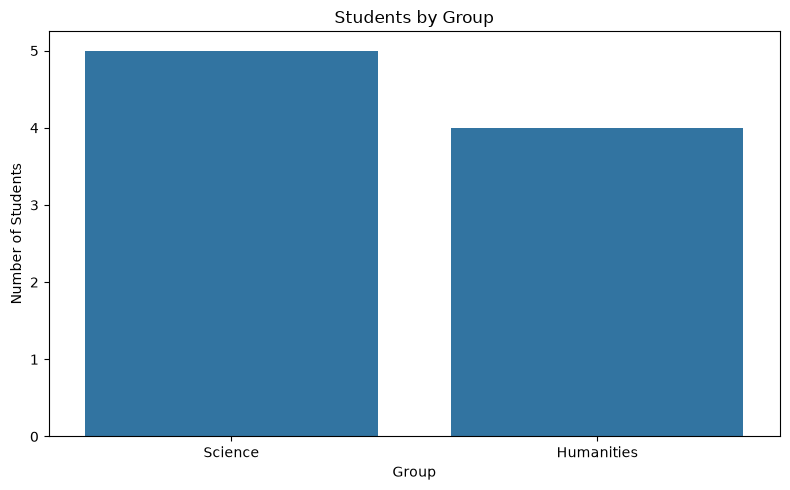

In [ ]:
# ============================================================
# GROUP DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Group")

plt.title("Students by Group")
plt.xlabel("Group")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

# 12. Best & Weakest Subject per Student

For each student we identify:

### Best Subject

The subject where the student obtained the highest mark.

### Weakest Subject

The subject where the student obtained the lowest mark.

We also display the actual marks for both subjects.


In [ ]:
# ============================================================
# BEST & WEAKEST SUBJECT PER STUDENT
# ============================================================

best_weakest = df[["Roll", "Name", "Group", "Gender", "GPA"]].copy()

# Best subject
best_weakest["Best_Subject"] = df[subject_columns].idxmax(axis=1)

best_weakest["Best_Mark"] = df[subject_columns].max(axis=1)

# Weakest subject
best_weakest["Weakest_Subject"] = df[subject_columns].idxmin(axis=1)

best_weakest["Weakest_Mark"] = df[subject_columns].min(axis=1)

display(best_weakest)

,Roll,Name,Group,Gender,GPA,Best_Subject,Best_Mark,Weakest_Subject,Weakest_Mark
0,105239,Sheikh Talha,Science,Male,4.00,English,136.0,ICT,43.0
1,105240,Tahia Sultana,Science,Female,4.22,Bangla,133.0,ICT,43.0
2,105241,Kazi Sadia Sultana Mahima,Science,Female,4.11,Bangla,116.0,ICT,45.0
3,105243,Toslima Begum,Science,Female,3.78,Bangla,112.0,Mathematics,41.0
4,105247,Kazi Mumina Akter Jui,Science,Female,3.39,Bangla,109.0,Mathematics,42.0
5,308975,Ariful Islam,Humanities,Male,0.00,Bangla,75.0,English,0.0
6,308026,Md Riyad,Humanities,Male,0.00,Bangla,76.0,English,0.0
7,308927,Mazedul Islam Naim,Humanities,Male,0.00,Bangla,90.0,English,0.0
8,308978,Test,Humanities,Female,0.00,Bangla,99.0,English,0.0


# 13. GPA Distribution

This visualization shows how GPA values are distributed among students.


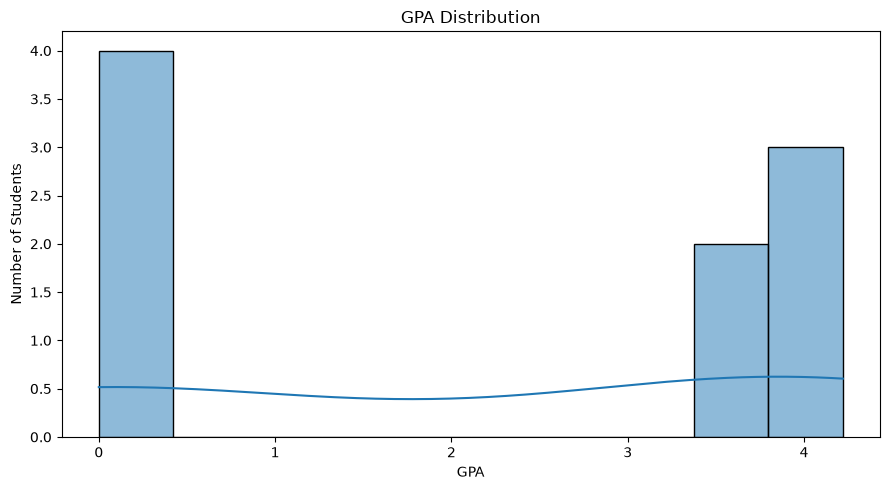

In [41]:
# ============================================================
# GPA DISTRIBUTION
# ============================================================

plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="GPA", bins=10, kde=True)

plt.title("GPA Distribution")
plt.xlabel("GPA")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

# 14. GPA by Group

A boxplot is used to compare GPA distributions between Science and Humanities.


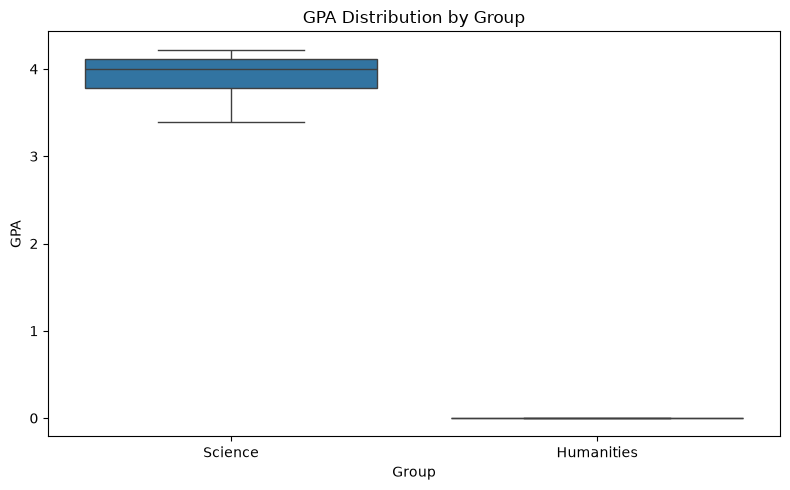

In [42]:
# ============================================================
# GPA BY GROUP
# ============================================================

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Group", y="GPA")

plt.title("GPA Distribution by Group")
plt.xlabel("Group")
plt.ylabel("GPA")

plt.tight_layout()
plt.show()

# 15. Final Academic Summary

The final section summarizes the most important findings from the dataset.


In [43]:
# ============================================================
# FINAL SUMMARY
# ============================================================

best_student = ranking.iloc[0]

weakest_subject = subject_analysis.iloc[0]

best_subject_overall = subject_analysis.sort_values("Average", ascending=False).iloc[0]

print("=" * 80)
print("                 FINAL ACADEMIC SUMMARY")
print("=" * 80)

print(f"\nTotal Students       : {total_students}")
print(f"Passed Students      : {passed_students}")
print(f"Failed Students      : {failed_students}")

print(f"\nOverall Pass Rate    : {pass_rate:.2f}%")
print(f"Overall Fail Rate    : {fail_rate:.2f}%")

print(f"\nAverage GPA          : {df['GPA'].mean():.2f}")
print(f"Highest GPA          : {df['GPA'].max():.2f}")
print(f"Lowest GPA           : {df['GPA'].min():.2f}")

print("\n" + "-" * 80)

print(f"🏆 Best Student      : {best_student['Name']}")
print(f"🏆 Best Student GPA  : {best_student['GPA']}")
print(f"🏆 Student Rank      : {best_student['Rank']}")

print("\n" + "-" * 80)

print(f"📚 Strongest Subject : {best_subject_overall['Subject']}")
print(f"📚 Average Mark      : {best_subject_overall['Average']}")

print("\n" + "-" * 80)

print(f"⚠️ Weakest Subject   : {weakest_subject['Subject']}")
print(f"⚠️ Average Mark      : {weakest_subject['Average']}")
print(f"⚠️ Failure Rate      : {weakest_subject['Fail_Rate_%']}%")

print("\n" + "=" * 80)
print("                 ANALYSIS COMPLETED")
print("=" * 80)

                 FINAL ACADEMIC SUMMARY

Total Students       : 9
Passed Students      : 5
Failed Students      : 4

Overall Pass Rate    : 55.56%
Overall Fail Rate    : 44.44%

Average GPA          : 2.17
Highest GPA          : 4.22
Lowest GPA           : 0.00

--------------------------------------------------------------------------------
🏆 Best Student      : Tahia Sultana
🏆 Best Student GPA  : 4.22
🏆 Student Rank      : 1

--------------------------------------------------------------------------------
📚 Strongest Subject : Bangla
📚 Average Mark      : 104.0

--------------------------------------------------------------------------------
⚠️ Weakest Subject   : Geography
⚠️ Average Mark      : 20.5
⚠️ Failure Rate      : 50.0%

                 ANALYSIS COMPLETED
